In [26]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import numpy as np
import os

In [2]:
conn = sqlite3.connect("olist.db")

files = {
    "orders": "olist_orders_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "products": "olist_products_dataset.csv",
    "order_reviews": "olist_order_reviews_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "customers": "olist_customers_dataset.csv",
    "category_translation": "product_category_name_translation.csv",
}

for table, file in files.items():
    df = pd.read_csv(file)
    df.to_sql(table + "_raw", conn, if_exists="replace", index=False)
    print(table + "_raw", len(df))

orders_raw 99441
order_items_raw 112650
products_raw 32951
order_reviews_raw 99224
sellers_raw 3095
customers_raw 99441
category_translation_raw 71


In [3]:
conn.executescript("""
PRAGMA foreign_keys = OFF;
DROP TABLE IF EXISTS order_reviews;
DROP TABLE IF EXISTS order_items;
DROP TABLE IF EXISTS orders;
DROP TABLE IF EXISTS products;
DROP TABLE IF EXISTS sellers;
DROP TABLE IF EXISTS customers;
DROP TABLE IF EXISTS category_translation;
DROP TABLE IF EXISTS orders_pk;
DROP TABLE IF EXISTS order_items_pk;
PRAGMA foreign_keys = ON;

CREATE TABLE customers (
    customer_id TEXT PRIMARY KEY,
    customer_unique_id TEXT,
    customer_zip_code_prefix INTEGER,
    customer_city TEXT,
    customer_state TEXT
);

CREATE TABLE sellers (
    seller_id TEXT PRIMARY KEY,
    seller_zip_code_prefix INTEGER,
    seller_city TEXT,
    seller_state TEXT
);

CREATE TABLE category_translation (
    product_category_name TEXT PRIMARY KEY,
    product_category_name_english TEXT
);

CREATE TABLE products (
    product_id TEXT PRIMARY KEY,
    product_category_name TEXT,
    product_name_lenght REAL,
    product_description_lenght REAL,
    product_photos_qty REAL,
    product_weight_g REAL,
    product_length_cm REAL,
    product_height_cm REAL,
    product_width_cm REAL
);

CREATE TABLE orders (
    order_id TEXT PRIMARY KEY,
    customer_id TEXT,
    order_status TEXT,
    order_purchase_timestamp TEXT,
    order_approved_at TEXT,
    order_delivered_carrier_date TEXT,
    order_delivered_customer_date TEXT,
    order_estimated_delivery_date TEXT,
    FOREIGN KEY (customer_id) REFERENCES customers(customer_id)
);

CREATE TABLE order_items (
    order_id TEXT,
    order_item_id INTEGER,
    product_id TEXT,
    seller_id TEXT,
    shipping_limit_date TEXT,
    price REAL,
    freight_value REAL,
    PRIMARY KEY (order_id, order_item_id),
    FOREIGN KEY (order_id) REFERENCES orders(order_id),
    FOREIGN KEY (product_id) REFERENCES products(product_id),
    FOREIGN KEY (seller_id) REFERENCES sellers(seller_id)
);

CREATE TABLE order_reviews (
    review_id TEXT,
    order_id TEXT,
    review_score INTEGER,
    review_comment_title TEXT,
    review_comment_message TEXT,
    review_creation_date TEXT,
    review_answer_timestamp TEXT,
    PRIMARY KEY (review_id, order_id),
    FOREIGN KEY (order_id) REFERENCES orders(order_id)
);

INSERT INTO customers SELECT * FROM customers_raw;
INSERT INTO sellers SELECT * FROM sellers_raw;
INSERT INTO category_translation SELECT * FROM category_translation_raw;
INSERT INTO products SELECT * FROM products_raw;
INSERT INTO orders SELECT * FROM orders_raw;
INSERT INTO order_items SELECT * FROM order_items_raw;
INSERT INTO order_reviews SELECT * FROM order_reviews_raw;

DROP TABLE orders_raw;
DROP TABLE order_items_raw;
DROP TABLE products_raw;
DROP TABLE order_reviews_raw;
DROP TABLE sellers_raw;
DROP TABLE customers_raw;
DROP TABLE category_translation_raw;
""")

for t in ["orders", "order_items", "products", "order_reviews",
          "sellers", "customers", "category_translation"]:
    n = pd.read_sql(f"SELECT COUNT(*) AS n FROM {t}", conn).iloc[0, 0]
    print(t, n)

orders 99441
order_items 112650
products 32951
order_reviews 99224
sellers 3095
customers 99441
category_translation 71


In [7]:
q1a = """
SELECT 'orders' AS table_name, COUNT(*) AS row_count FROM orders
UNION ALL SELECT 'order_items', COUNT(*) FROM order_items
UNION ALL SELECT 'products', COUNT(*) FROM products
UNION ALL SELECT 'order_reviews', COUNT(*) FROM order_reviews
UNION ALL SELECT 'sellers', COUNT(*) FROM sellers
UNION ALL SELECT 'customers', COUNT(*) FROM customers
UNION ALL SELECT 'category_translation', COUNT(*) FROM category_translation
"""
print(pd.read_sql(q1a, conn))

q1b = """
SELECT
    (SELECT COUNT(*) FROM orders) AS total_orders,
    (SELECT COUNT(DISTINCT order_id) FROM order_items) AS orders_with_items,
    (SELECT COUNT(*) FROM order_items) AS total_items,
    ROUND(1.0 * (SELECT COUNT(*) FROM order_items)
          / (SELECT COUNT(*) FROM orders), 2) AS avg_items_all_orders,
    ROUND(1.0 * (SELECT COUNT(*) FROM order_items)
          / (SELECT COUNT(DISTINCT order_id) FROM order_items), 2) AS avg_items_per_order_with_items
"""
print(pd.read_sql(q1b, conn))

q1c = """
SELECT items_in_order, COUNT(*) AS n_orders
FROM (
    SELECT order_id, COUNT(*) AS items_in_order
    FROM order_items
    GROUP BY order_id
)
GROUP BY items_in_order
ORDER BY items_in_order
"""
print(pd.read_sql(q1c, conn))  #Q1

             table_name  row_count
0                orders      99441
1           order_items     112650
2              products      32951
3         order_reviews      99224
4               sellers       3095
5             customers      99441
6  category_translation         71
   total_orders  orders_with_items  total_items  avg_items_all_orders  \
0         99441              98666       112650                  1.13   

   avg_items_per_order_with_items  
0                            1.14  
    items_in_order  n_orders
0                1     88863
1                2      7516
2                3      1322
3                4       505
4                5       204
5                6       198
6                7        22
7                8         8
8                9         3
9               10         8
10              11         4
11              12         5
12              13         1
13              14         2
14              15         2
15              20         2
16      

In [8]:
conn.executescript("""
DROP VIEW IF EXISTS analytical_base;

CREATE VIEW analytical_base AS
SELECT
    o.order_id,
    o.customer_id,
    oi.order_item_id,
    oi.product_id,
    oi.seller_id,
    oi.price,
    oi.freight_value,
    p.product_category_name,
    ct.product_category_name_english AS category,
    r.review_id,
    r.review_score,
    o.order_purchase_timestamp,
    o.order_delivered_customer_date,
    o.order_estimated_delivery_date,
    strftime('%Y-%m', o.order_purchase_timestamp) AS order_month,
    julianday(o.order_delivered_customer_date)
      - julianday(o.order_purchase_timestamp) AS delivery_days
FROM orders o
INNER JOIN order_items oi ON oi.order_id = o.order_id
LEFT JOIN products p ON p.product_id = oi.product_id
LEFT JOIN category_translation ct ON ct.product_category_name = p.product_category_name
LEFT JOIN order_reviews r ON r.order_id = o.order_id
WHERE o.order_status = 'delivered';
""")  #Q2

In [9]:
print(pd.read_sql("SELECT COUNT(*) AS n FROM analytical_base", conn))

        n
0  110840


In [10]:
q3 = """
SELECT
    (SELECT ROUND(SUM(oi.price), 2)
     FROM order_items oi
     JOIN orders o ON o.order_id = oi.order_id
     WHERE o.order_status = 'delivered') AS revenue_a_direct,
    (SELECT ROUND(SUM(price), 2) FROM analytical_base) AS revenue_b_view,
    (SELECT COUNT(*)
     FROM order_items oi
     JOIN orders o ON o.order_id = oi.order_id
     WHERE o.order_status = 'delivered') AS rows_a,
    (SELECT COUNT(*) FROM analytical_base) AS rows_b
"""
print(pd.read_sql(q3, conn))  #Q3

   revenue_a_direct  revenue_b_view  rows_a  rows_b
0       13221498.11     13279836.59  110197  110840


In [11]:
conn.executescript("""
DROP VIEW IF EXISTS analytical_base;

CREATE VIEW analytical_base AS
WITH reviews_per_order AS (
    SELECT order_id,
           AVG(review_score) AS review_score,
           COUNT(*) AS n_reviews
    FROM order_reviews
    GROUP BY order_id
)
SELECT
    o.order_id,
    o.customer_id,
    oi.order_item_id,
    oi.product_id,
    oi.seller_id,
    oi.price,
    oi.freight_value,
    p.product_category_name,
    ct.product_category_name_english AS category,
    r.review_score,
    o.order_purchase_timestamp,
    o.order_delivered_customer_date,
    o.order_estimated_delivery_date,
    strftime('%Y-%m', o.order_purchase_timestamp) AS order_month,
    julianday(o.order_delivered_customer_date)
      - julianday(o.order_purchase_timestamp) AS delivery_days
FROM orders o
INNER JOIN order_items oi ON oi.order_id = o.order_id
LEFT JOIN products p ON p.product_id = oi.product_id
LEFT JOIN category_translation ct ON ct.product_category_name = p.product_category_name
LEFT JOIN reviews_per_order r ON r.order_id = o.order_id
WHERE o.order_status = 'delivered';
""") #Q3

In [12]:
print(pd.read_sql(q3, conn))

   revenue_a_direct  revenue_b_view  rows_a  rows_b
0       13221498.11     13221498.11  110197  110197


In [24]:
q2_steps = """
SELECT '1. delivered orders' AS step, COUNT(*) AS rows_
FROM orders WHERE order_status = 'delivered'
UNION ALL
SELECT '2. + order_items (INNER)', COUNT(*)
FROM orders o JOIN order_items oi ON oi.order_id = o.order_id
WHERE o.order_status = 'delivered'
UNION ALL
SELECT '3. + products (LEFT)', COUNT(*)
FROM orders o JOIN order_items oi ON oi.order_id = o.order_id
LEFT JOIN products p ON p.product_id = oi.product_id
WHERE o.order_status = 'delivered'
UNION ALL
SELECT '4. + category_translation (LEFT)', COUNT(*)
FROM orders o JOIN order_items oi ON oi.order_id = o.order_id
LEFT JOIN products p ON p.product_id = oi.product_id
LEFT JOIN category_translation ct ON ct.product_category_name = p.product_category_name
WHERE o.order_status = 'delivered'
UNION ALL
SELECT '5. + order_reviews raw (LEFT, qruplaşdırmadan)', COUNT(*)
FROM orders o JOIN order_items oi ON oi.order_id = o.order_id
LEFT JOIN products p ON p.product_id = oi.product_id
LEFT JOIN category_translation ct ON ct.product_category_name = p.product_category_name
LEFT JOIN order_reviews r ON r.order_id = o.order_id
WHERE o.order_status = 'delivered'
UNION ALL
SELECT '6. final view (reviews qruplaşdırılıb)', COUNT(*) FROM analytical_base
"""
print(pd.read_sql(q2_steps, conn))

                                             step   rows_
0                             1. delivered orders   96478
1                        2. + order_items (INNER)  110197
2                            3. + products (LEFT)  110197
3                4. + category_translation (LEFT)  110197
4  5. + order_reviews raw (LEFT, qruplaşdırmadan)  110840
5          6. final view (reviews qruplaşdırılıb)  110197


In [13]:
q4 = """
WITH order_level AS (
    SELECT order_id,
           SUM(price) AS revenue,
           MAX(delivery_days) AS delivery_days,
           MAX(review_score) AS review_score
    FROM analytical_base
    GROUP BY order_id
)
SELECT
    COUNT(*) AS n_orders,
    ROUND(SUM(revenue), 2) AS total_revenue,
    ROUND(SUM(revenue) * 1.0 / COUNT(*), 2) AS aov,
    ROUND(AVG(delivery_days), 2) AS avg_delivery_days,
    ROUND(AVG(review_score), 2) AS avg_review_score
FROM order_level
"""
print(pd.read_sql(q4, conn))  #Q4

   n_orders  total_revenue     aov  avg_delivery_days  avg_review_score
0     96478    13221498.11  137.04              12.56              4.16


In [14]:
q5 = """
WITH order_cat AS (
    SELECT order_id,
           COALESCE(category, 'unknown') AS category,
           SUM(price) AS revenue,
           MAX(delivery_days) AS delivery_days,
           MAX(review_score) AS review_score
    FROM analytical_base
    GROUP BY order_id, COALESCE(category, 'unknown')
)
SELECT
    category,
    COUNT(*) AS n_orders,
    ROUND(SUM(revenue), 2) AS total_revenue,
    ROUND(SUM(revenue) * 1.0 / COUNT(*), 2) AS aov,
    ROUND(AVG(delivery_days), 2) AS avg_delivery_days,
    ROUND(AVG(review_score), 2) AS avg_review_score
FROM order_cat
GROUP BY category
ORDER BY total_revenue DESC
"""
df_q5 = pd.read_sql(q5, conn)
print(df_q5.head(10))
print(len(df_q5), "categories") #Q5

                category  n_orders  total_revenue     aov  avg_delivery_days  \
0          health_beauty      8647     1233131.72  142.61              12.08   
1          watches_gifts      5495     1166176.98  212.23              12.81   
2         bed_bath_table      9272     1023434.76  110.38              12.99   
3         sports_leisure      7530      954852.55  126.81              12.24   
4  computers_accessories      6530      888724.61  136.10              13.17   
5        furniture_decor      6307      711927.69  112.88              13.07   
6             housewares      5743      615628.69  107.20              11.09   
7             cool_stuff      3559      610204.10  171.45              12.38   
8                   auto      3810      578966.65  151.96              12.33   
9                   toys      3804      471286.48  123.89              11.73   

   avg_review_score  
0              4.23  
1              4.12  
2              4.00  
3              4.23  
4        

In [15]:
q6 = """
WITH order_level AS (
    SELECT order_id,
           order_month,
           SUM(price) AS revenue,
           MAX(delivery_days) AS delivery_days,
           MAX(review_score) AS review_score
    FROM analytical_base
    GROUP BY order_id, order_month
)
SELECT
    order_month,
    COUNT(*) AS n_orders,
    ROUND(SUM(revenue), 2) AS total_revenue,
    ROUND(SUM(revenue) * 1.0 / COUNT(*), 2) AS aov,
    ROUND(AVG(delivery_days), 2) AS avg_delivery_days,
    ROUND(AVG(review_score), 2) AS avg_review_score
FROM order_level
GROUP BY order_month
ORDER BY order_month
"""
df_q6 = pd.read_sql(q6, conn)
print(df_q6)  #Q6

   order_month  n_orders  total_revenue     aov  avg_delivery_days  \
0      2016-09         1         134.97  134.97              54.81   
1      2016-10       265       40325.11  152.17              19.60   
2      2016-12         1          10.90   10.90               4.69   
3      2017-01       750      111798.36  149.06              12.65   
4      2017-02      1653      234223.40  141.70              13.17   
5      2017-03      2546      359198.85  141.08              12.95   
6      2017-04      2303      340669.68  147.92              14.92   
7      2017-05      3546      489338.25  138.00              11.32   
8      2017-06      3135      421923.37  134.58              12.01   
9      2017-07      3872      481604.52  124.38              11.59   
10     2017-08      4193      554699.70  132.29              11.15   
11     2017-09      4150      607399.67  146.36              11.85   
12     2017-10      4478      648247.65  144.76              11.86   
13     2017-11      

In [16]:
q7 = """
WITH order_cat AS (
    SELECT order_id,
           COALESCE(category, 'unknown') AS category,
           SUM(price) AS revenue
    FROM analytical_base
    GROUP BY order_id, COALESCE(category, 'unknown')
),
cat AS (
    SELECT category,
           COUNT(*) AS n_orders,
           ROUND(SUM(revenue), 2) AS total_revenue
    FROM order_cat
    WHERE category <> 'unknown'
    GROUP BY category
)
SELECT * FROM (
    SELECT 'top 5' AS segment, category, n_orders, total_revenue
    FROM cat ORDER BY total_revenue DESC LIMIT 5
)
UNION ALL
SELECT * FROM (
    SELECT 'bottom 5' AS segment, category, n_orders, total_revenue
    FROM cat ORDER BY total_revenue ASC LIMIT 5
)
"""
df_q7 = pd.read_sql(q7, conn)
print(df_q7) #Q7

    segment                   category  n_orders  total_revenue
0     top 5              health_beauty      8647     1233131.72
1     top 5              watches_gifts      5495     1166176.98
2     top 5             bed_bath_table      9272     1023434.76
3     top 5             sports_leisure      7530      954852.55
4     top 5      computers_accessories      6530      888724.61
5  bottom 5      security_and_services         2         283.29
6  bottom 5  fashion_childrens_clothes         7         519.95
7  bottom 5          cds_dvds_musicals        12         730.00
8  bottom 5             home_comfort_2        24         760.27
9  bottom 5                    flowers        29        1110.04


In [17]:
q8 = """
WITH order_cat AS (
    SELECT order_id,
           COALESCE(category, 'unknown') AS category,
           MAX(review_score) AS review_score
    FROM analytical_base
    GROUP BY order_id, COALESCE(category, 'unknown')
),
cat AS (
    SELECT category,
           COUNT(DISTINCT order_id) AS n_orders,
           ROUND(AVG(review_score), 2) AS avg_review_score
    FROM order_cat
    WHERE category <> 'unknown'
    GROUP BY category
    HAVING COUNT(DISTINCT order_id) >= 100
)
SELECT * FROM (
    SELECT 'top 5' AS segment, category, n_orders, avg_review_score
    FROM cat ORDER BY avg_review_score DESC LIMIT 5
)
UNION ALL
SELECT * FROM (
    SELECT 'bottom 5' AS segment, category, n_orders, avg_review_score
    FROM cat ORDER BY avg_review_score ASC LIMIT 5
)
"""
df_q8 = pd.read_sql(q8, conn)
print(df_q8) #Q8

    segment                   category  n_orders  avg_review_score
0     top 5     books_general_interest       496              4.53
1     top 5                 food_drink       221              4.45
2     top 5            books_technical       256              4.43
3     top 5        luggage_accessories      1019              4.37
4     top 5                       food       441              4.33
5  bottom 5           office_furniture      1254              3.64
6  bottom 5      fashion_male_clothing       106              3.82
7  bottom 5                      audio       348              3.84
8  bottom 5               home_confort       392              3.89
9  bottom 5  construction_tools_safety       159              3.97


In [18]:
q9 = """
WITH order_seller AS (
    SELECT order_id,
           seller_id,
           SUM(price) AS revenue,
           MAX(delivery_days) AS delivery_days,
           MAX(review_score) AS review_score
    FROM analytical_base
    GROUP BY order_id, seller_id
),
seller_kpi AS (
    SELECT seller_id,
           COUNT(*) AS n_orders,
           ROUND(SUM(revenue), 2) AS total_revenue,
           ROUND(AVG(review_score), 2) AS avg_review_score,
           ROUND(AVG(delivery_days), 2) AS avg_delivery_days
    FROM order_seller
    GROUP BY seller_id
)
SELECT RANK() OVER (ORDER BY total_revenue DESC) AS revenue_rank,
       *
FROM seller_kpi
ORDER BY revenue_rank
"""
df_q9 = pd.read_sql(q9, conn)
print(df_q9.head(10))
print(len(df_q9), "sellers") #Q9

   revenue_rank                         seller_id  n_orders  total_revenue  \
0             1  4869f7a5dfa277a7dca6462dcf3b52b2      1124      226987.93   
1             2  53243585a1d6dc2643021fd1853d8905       348      217940.44   
2             3  4a3ca9315b744ce9f8e9374361493884      1772      196882.12   
3             4  fa1c13f2614d7b5c4749cbc52fecda94       578      190917.14   
4             5  7c67e1448b00f6e969d365cea6b010ab       973      186570.05   
5             6  7e93a43ef30c4f03f38b393420bc753a       319      165981.49   
6             7  da8622b14eb17ae2831f4ac5b9dab84a      1311      159816.87   
7             8  7a67c85e85bb2ce8582c35f2203ad736      1145      139658.69   
8             9  1025f0e2d44d7041d6cf58b6550e0bfa       910      138208.56   
9            10  955fee9216a65b617aa5c0531780ce60      1261      131836.71   

   avg_review_score  avg_delivery_days  
0              4.15              15.06  
1              4.19              13.43  
2              3.8

In [19]:
q10 = """
WITH order_cat AS (
    SELECT order_id,
           COALESCE(category, 'unknown') AS category,
           MAX(delivery_days) AS delivery_days,
           MAX(review_score) AS review_score
    FROM analytical_base
    GROUP BY order_id, COALESCE(category, 'unknown')
)
SELECT category,
       COUNT(DISTINCT order_id) AS n_orders,
       ROUND(AVG(delivery_days), 2) AS avg_delivery_days,
       ROUND(AVG(review_score), 2) AS avg_review_score
FROM order_cat
WHERE category <> 'unknown'
GROUP BY category
HAVING COUNT(DISTINCT order_id) >= 100
ORDER BY avg_delivery_days
"""
df_q10 = pd.read_sql(q10, conn)
print(df_q10.head(10))
print(len(df_q10), "categories") #Q10

                          category  n_orders  avg_delivery_days  \
0                             food       441               9.79   
1        construction_tools_lights       242               9.83   
2                           drinks       287              10.38   
3                  books_technical       256              10.63   
4                       food_drink       221              10.82   
5  construction_tools_construction       736              10.86   
6              luggage_accessories      1019              10.87   
7           signaling_and_security       138              10.87   
8   industry_commerce_and_business       232              10.89   
9                 small_appliances       609              10.98   

   avg_review_score  
0              4.33  
1              4.15  
2              4.24  
3              4.43  
4              4.45  
5              4.13  
6              4.37  
7              4.12  
8              4.22  
9              4.26  
51 categories


In [20]:
r_pearson = df_q10["avg_delivery_days"].corr(df_q10["avg_review_score"])
r_spearman = df_q10["avg_delivery_days"].corr(df_q10["avg_review_score"], method="spearman")

print("Kateqoriya sayı:", len(df_q10))
print("Pearson r :", round(r_pearson, 3))
print("Spearman r:", round(r_spearman, 3))

Kateqoriya sayı: 51
Pearson r : -0.585
Spearman r: -0.509


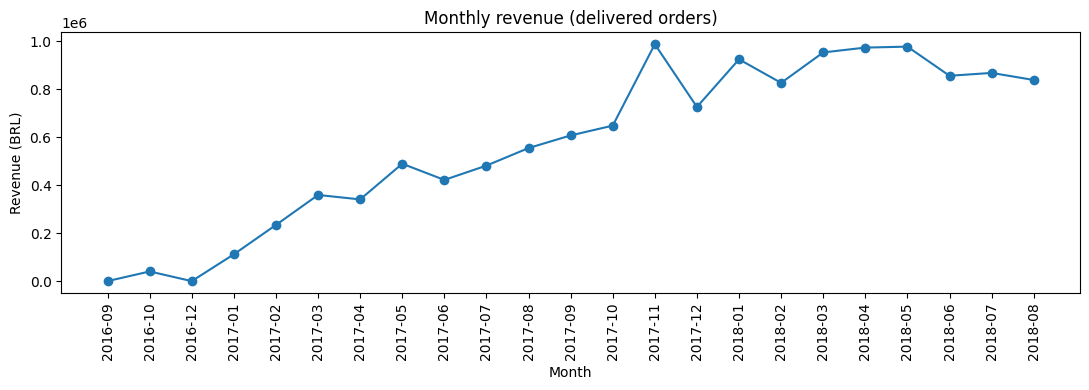

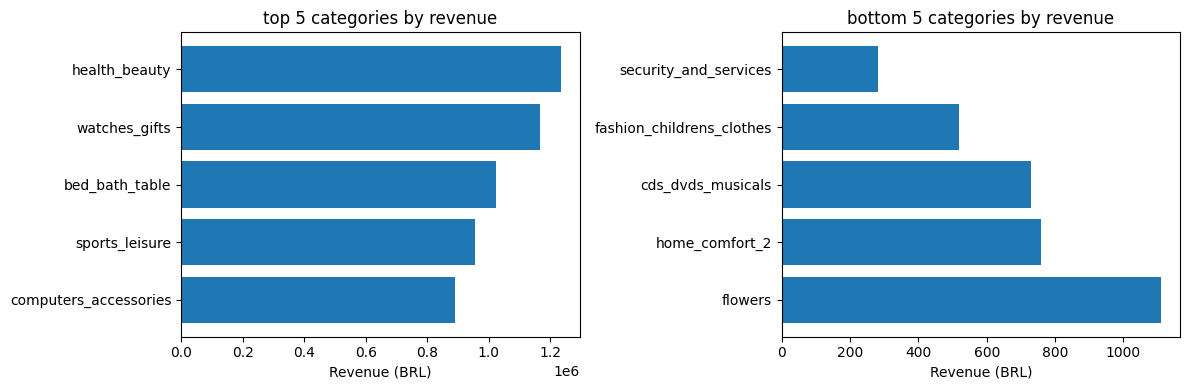

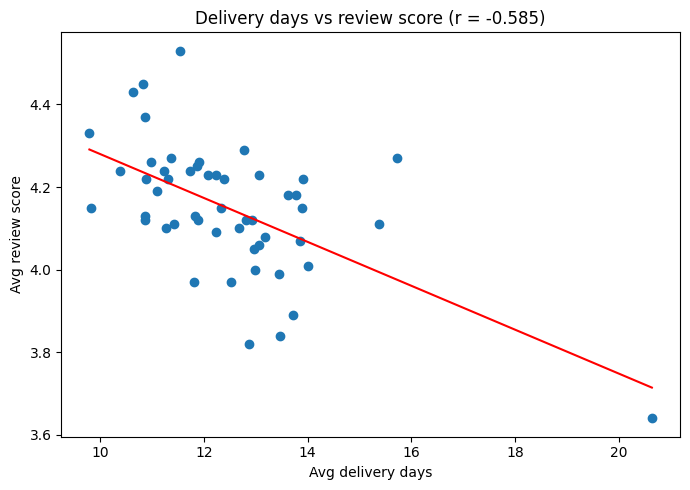

In [23]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df_q6["order_month"], df_q6["total_revenue"], marker="o")
ax.set_title("Monthly revenue (delivered orders)")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (BRL)")
ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, seg in zip(axes, ["top 5", "bottom 5"]):
    d = df_q7[df_q7["segment"] == seg]
    ax.barh(d["category"], d["total_revenue"])
    ax.invert_yaxis()
    ax.set_title(f"{seg} categories by revenue")
    ax.set_xlabel("Revenue (BRL)")
plt.tight_layout()
plt.show()

x = df_q10["avg_delivery_days"]
y = df_q10["avg_review_score"]
slope, intercept = np.polyfit(x, y, 1)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(x, y)
xs = np.linspace(x.min(), x.max(), 100)
ax.plot(xs, slope * xs + intercept, color="red")
ax.set_title(f"Delivery days vs review score (r = {r_pearson:.3f})")
ax.set_xlabel("Avg delivery days")
ax.set_ylabel("Avg review score")
plt.tight_layout()
plt.show()

In [25]:
print(pd.read_sql("""
SELECT o.order_status, COUNT(*) AS n
FROM orders o
LEFT JOIN order_items oi ON oi.order_id = o.order_id
WHERE oi.order_id IS NULL
GROUP BY o.order_status
""", conn))

  order_status    n
0     canceled  164
1      created    5
2     invoiced    2
3      shipped    1
4  unavailable  603
